In [1]:
!nvidia-smi

Tue May 20 07:46:01 2025       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 570.124.06             Driver Version: 570.124.06     CUDA Version: 12.8     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-SXM4-40GB          Off |   00000000:00:04.0 Off |                    0 |
| N/A   31C    P0             45W /  400W |       1MiB /  40960MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

In [2]:
import os
HOME = os.getcwd()
print(HOME)

/content


## Install YOLOv8

YOLOv8 can be installed in two ways - from the source and via pip. This is because it is the first iteration of YOLO to have an official package.

In [3]:
# Pip install method (recommended)

!pip install ultralytics==8.2.103 -q

from IPython import display
display.clear_output()

import ultralytics
ultralytics.checks()

Ultralytics YOLOv8.2.103 🚀 Python-3.10.12 torch-2.5.1+cu121 CUDA:0 (NVIDIA A100-SXM4-40GB, 40442MiB)
Setup complete ✅ (12 CPUs, 83.5 GB RAM, 41.9/94.3 GB disk)


In [4]:
from ultralytics import YOLO

from IPython.display import display, Image

In [5]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="YKjKJq9jwCbXAUxun5s3")
project = rf.workspace("work-4u6cx").project("yolv5-detection")
version = project.version(2)
dataset = version.download("yolov8")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 85.4/85.4 kB 5.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.8/66.8 kB 12.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 76.9 MB/s eta 0:00:00
  Attempting uninstall: idna
    Found existing installation: idna 3.10
    Uninstalling idna-3.10:
      Successfully uninstalled idna-3.10
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-genai 1.13.0 requires anyio<5.0.0,>=4.8.0, but you have anyio 3.7.1 which is incompatible.
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to YOLV5-Detection-2 in yolov8:: 100%|██████████| 6858/6858 [00:00<00:00, 7726.50it/s]


## Custom Training

In [6]:
!pip uninstall -y ray
!pip uninstall ray tune-sklearn

Found existing installation: ray 2.33.0
Uninstalling ray-2.33.0:
  Successfully uninstalled ray-2.33.0


In [7]:
%cd {HOME}

!yolo task=detect mode=train model=yolov8s.pt data={dataset.location}/data.yaml epochs=300 imgsz=800 plots=True

/content
100% 21.5M/21.5M [00:00<00:00, 159MB/s]
New https://pypi.org/project/ultralytics/8.3.140 available 😃 Update with 'pip install -U ultralytics'
Ultralytics YOLOv8.2.103 🚀 Python-3.10.12 torch-2.5.1+cu121 CUDA:0 (NVIDIA A100-SXM4-40GB, 40442MiB)
engine/trainer: task=detect, mode=train, model=yolov8s.pt, data=/content/YOLV5-Detection-2/data.yaml, epochs=300, time=None, patience=100, batch=16, imgsz=800, save=True, save_period=-1, cache=False, device=None, workers=8, project=None, name=train, exist_ok=False, pretrained=True, optimizer=auto, verbose=True, seed=0, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, save_hybrid=False, conf=None, iou=0.7, max_det=300, half=False, dnn=False, plots=True, source=None, vid_stride=1, stream_buffer=False, visualize=False, augment=False, agnostic_n

/content


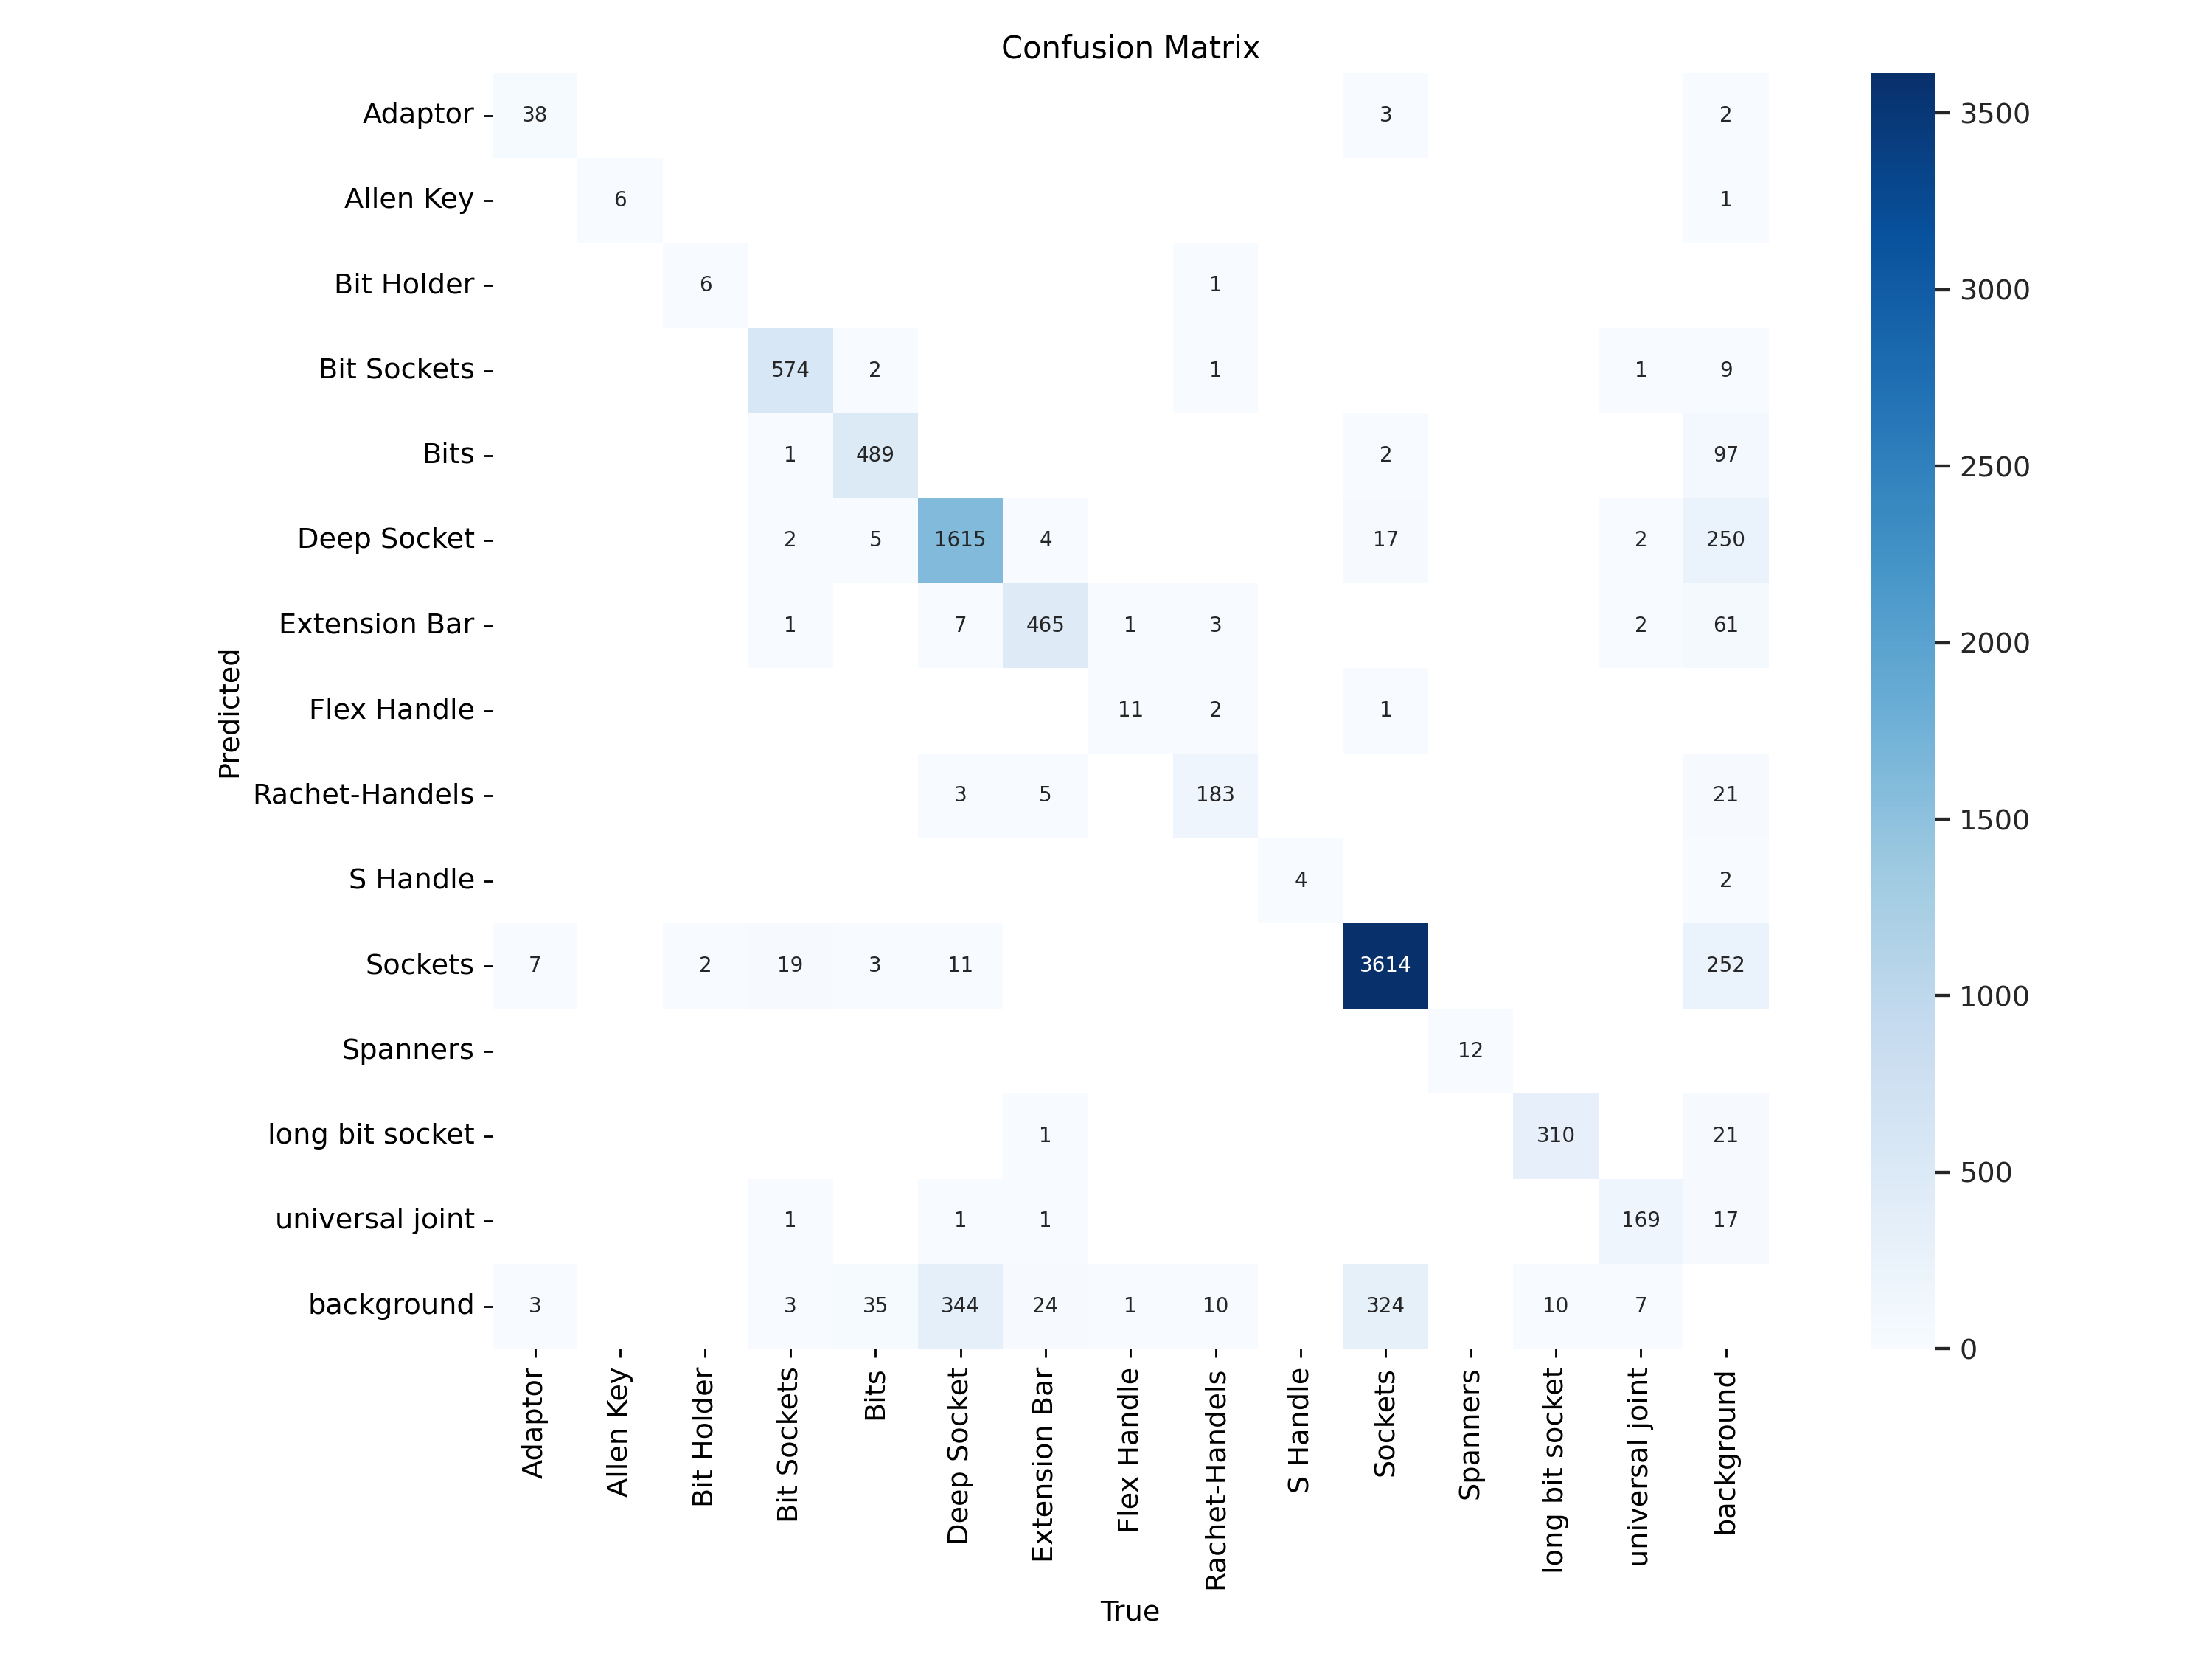

In [8]:
%cd {HOME}
Image(filename=f'{HOME}/runs/detect/train/confusion_matrix.png', width=600)

/content


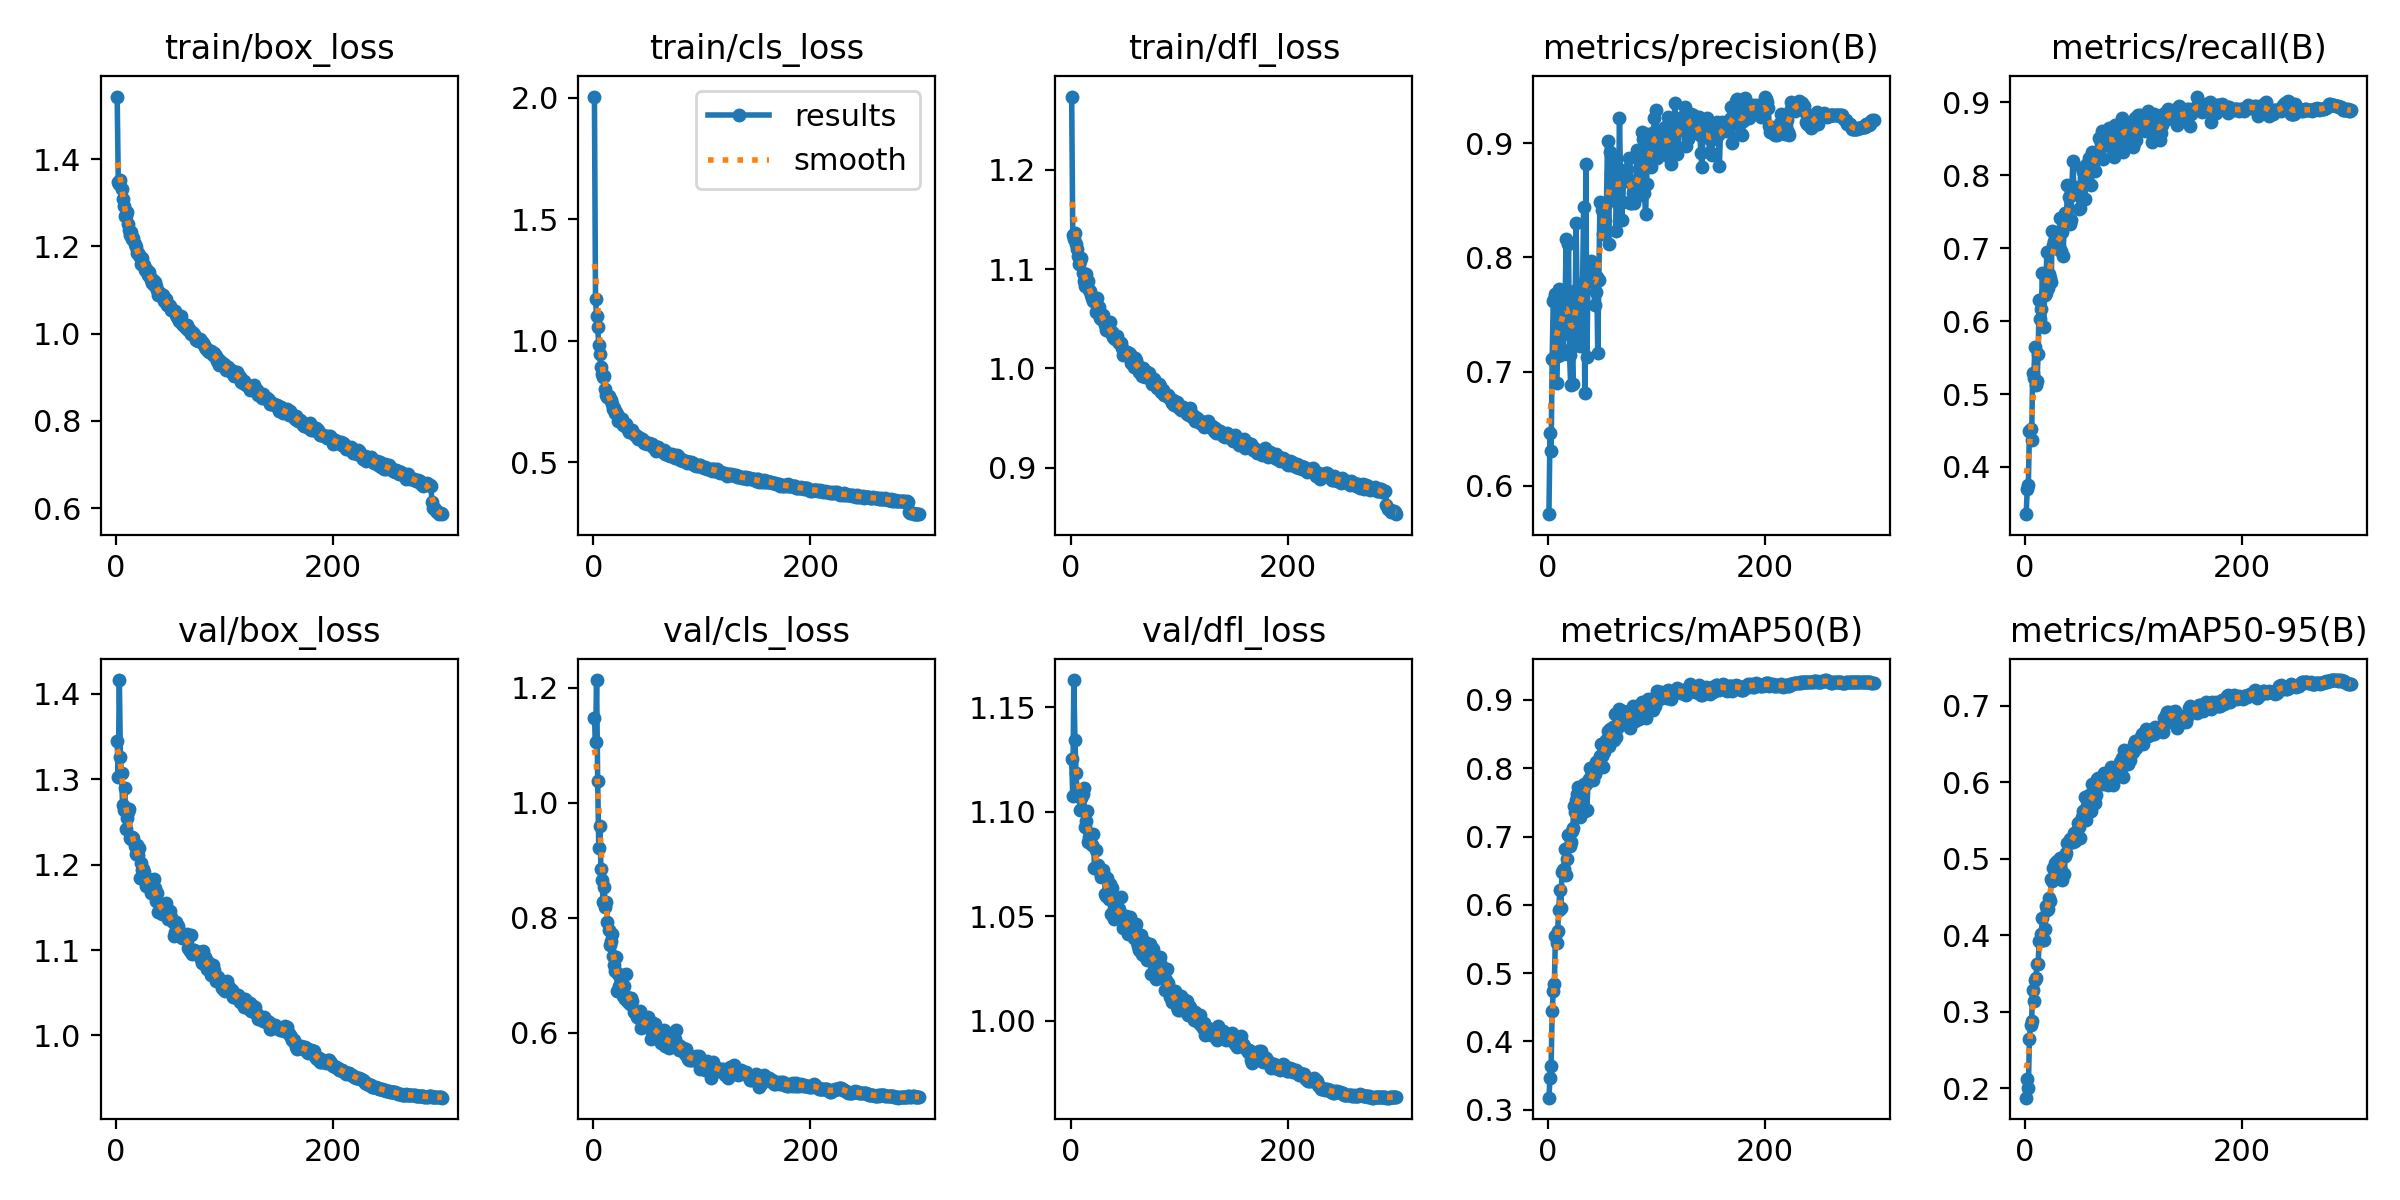

In [9]:
%cd {HOME}
Image(filename=f'{HOME}/runs/detect/train/results.png', width=600)

/content


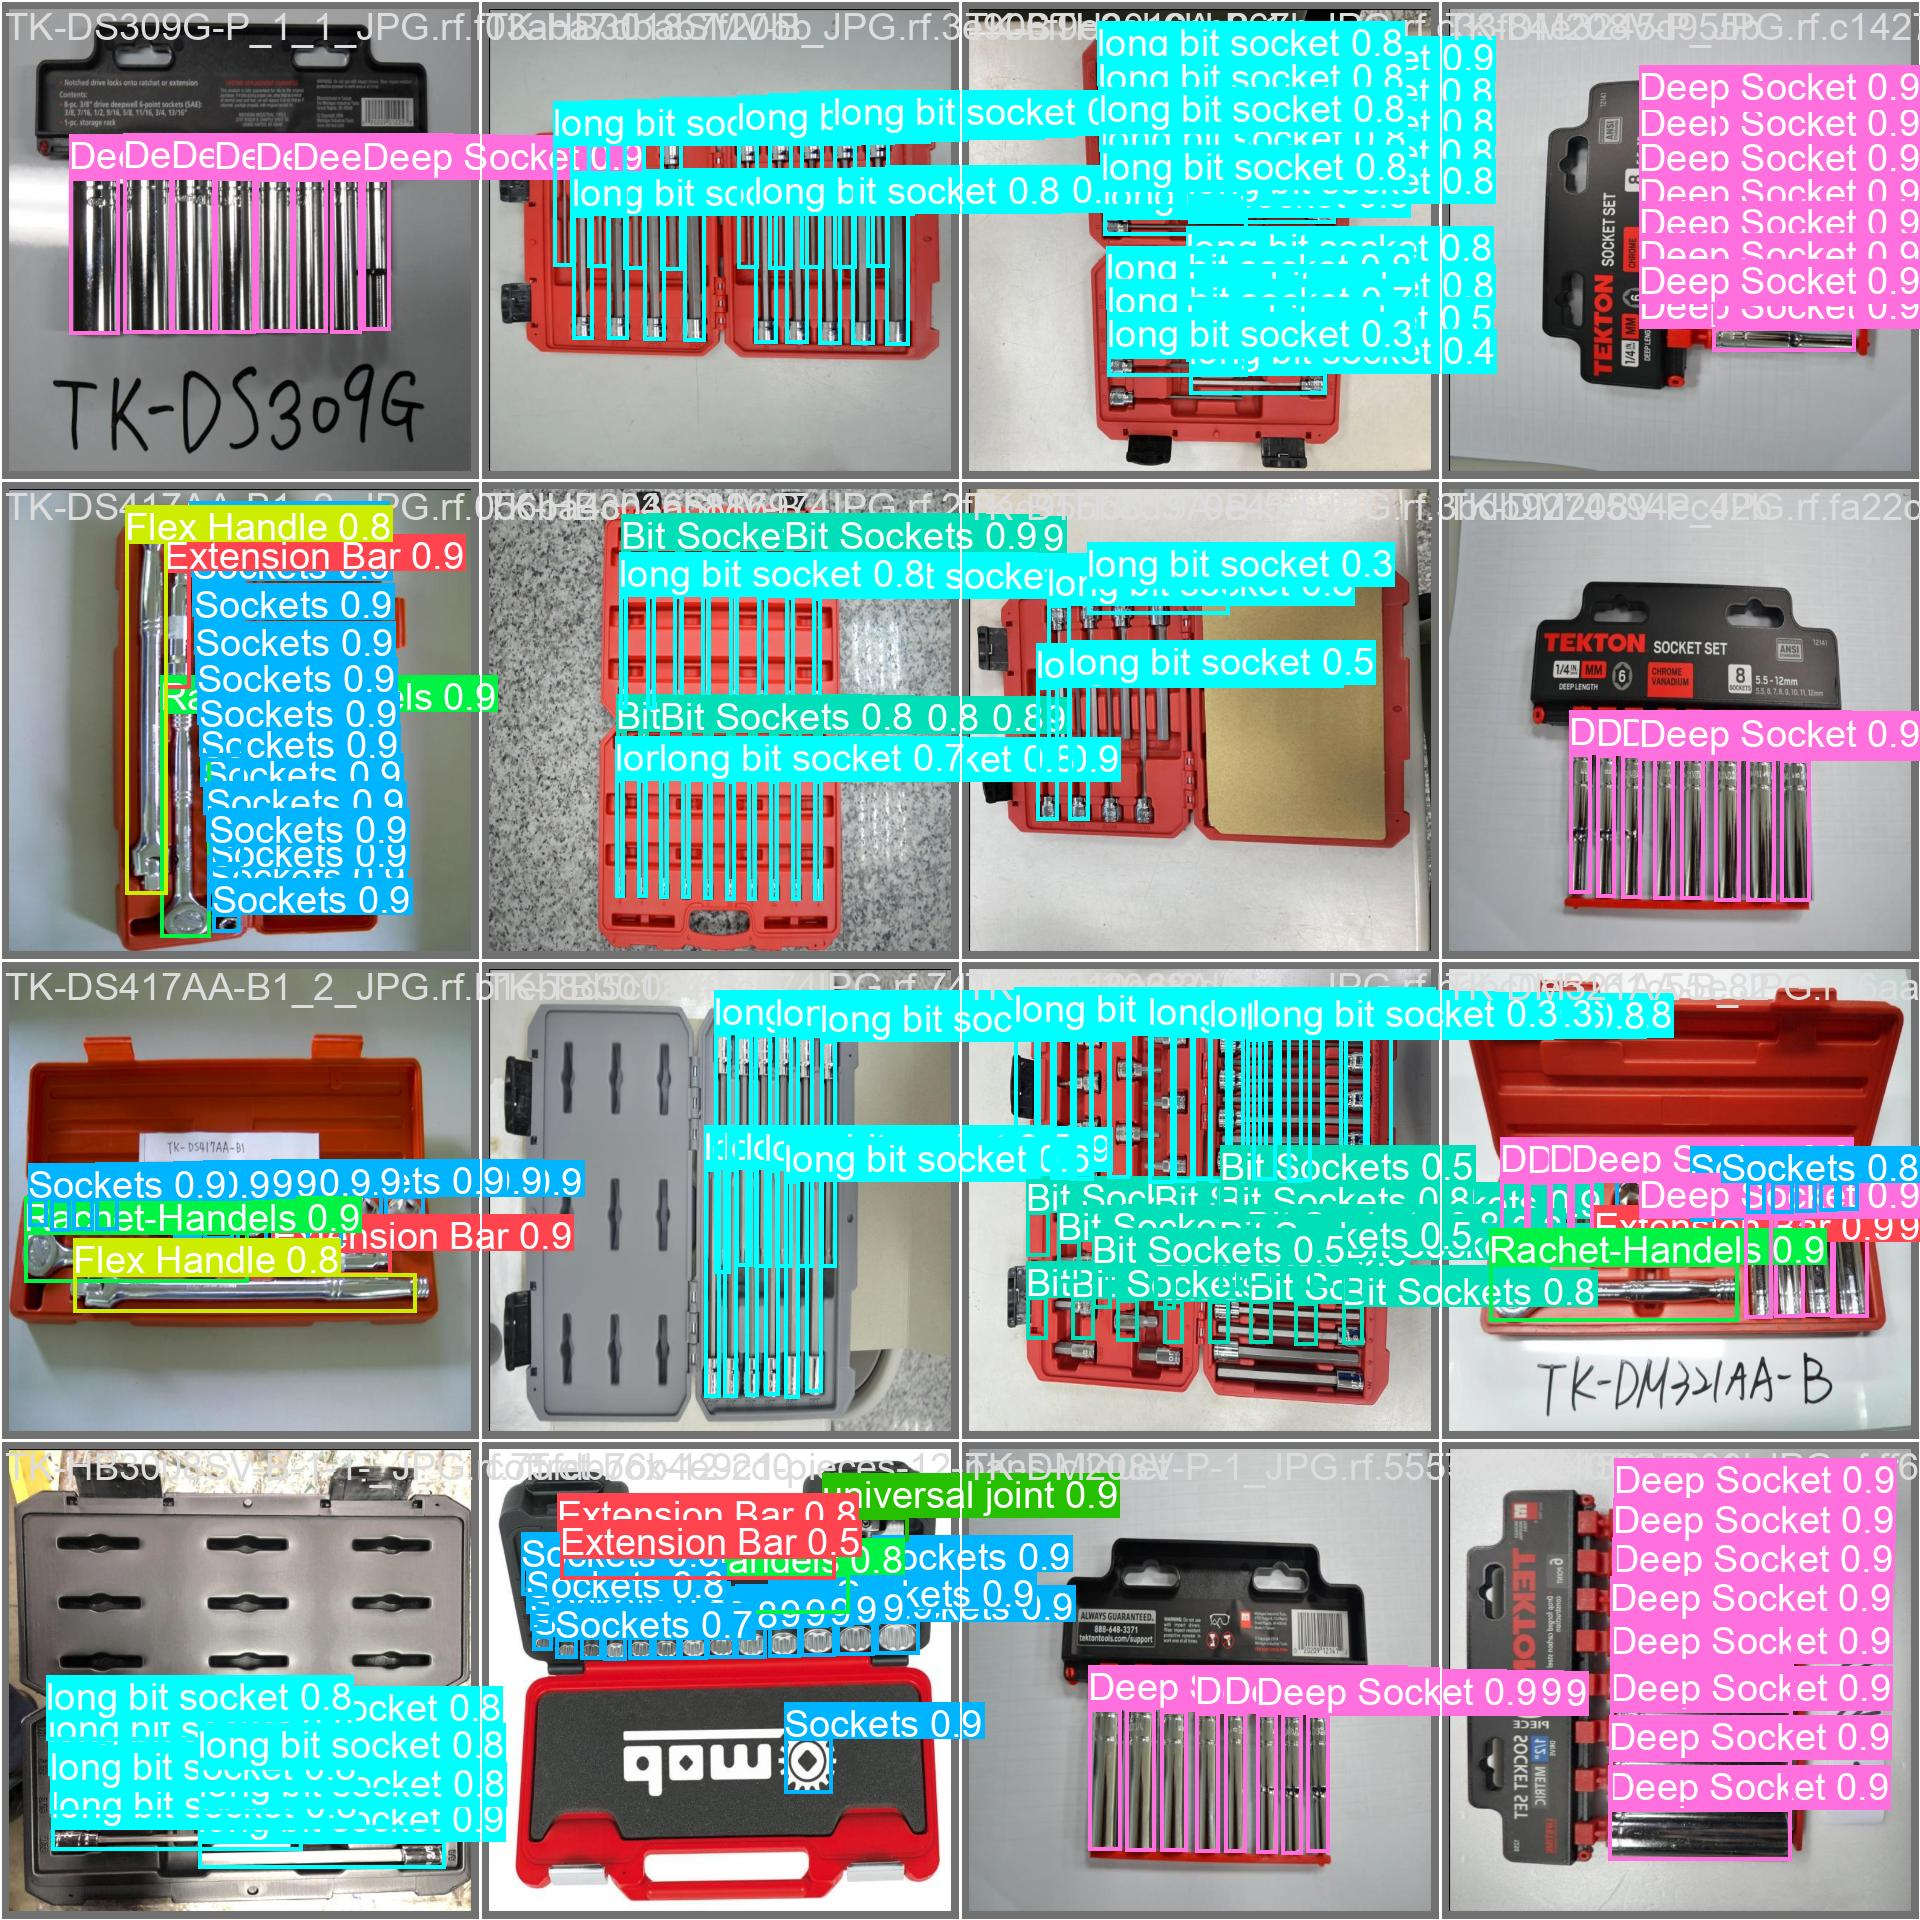

In [10]:
%cd {HOME}
Image(filename=f'{HOME}/runs/detect/train/val_batch0_pred.jpg', width=600)

## Validate Custom Model

In [11]:
%cd {HOME}

!yolo task=detect mode=val model={HOME}/runs/detect/train/weights/best.pt data={dataset.location}/data.yaml

/content
Ultralytics YOLOv8.2.103 🚀 Python-3.10.12 torch-2.5.1+cu121 CUDA:0 (NVIDIA A100-SXM4-40GB, 40442MiB)
Model summary (fused): 168 layers, 11,131,002 parameters, 0 gradients, 28.5 GFLOPs
val: Scanning /content/YOLV5-Detection-2/valid/labels.cache... 284 images, 0 backgrounds, 0 corrupt: 100% 284/284 [00:00<?, ?it/s]
WARNING ⚠️ Box and segment counts should be equal, but got len(segments) = 497, len(boxes) = 8369. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% 18/18 [00:08<00:00,  2.18it/s]
                   all        284       8369      0.913      0.896      0.926      0.731
               Adaptor         34         48      0.927      0.791      0.853      0.707
             Allen Key          6          6       0.83          1      0.995      0.873
          

## Inference with Custom Model

In [12]:
%cd {HOME}
!yolo task=detect mode=predict model={HOME}/runs/detect/train/weights/best.pt conf=0.25 source={dataset.location}/test/images save=True

/content
Ultralytics YOLOv8.2.103 🚀 Python-3.10.12 torch-2.5.1+cu121 CUDA:0 (NVIDIA A100-SXM4-40GB, 40442MiB)
Model summary (fused): 168 layers, 11,131,002 parameters, 0 gradients, 28.5 GFLOPs

image 1/141 /content/YOLV5-Detection-2/test/images/1-2-drive-flat-socket-spanners-500x500_webp.rf.334e032ed87e1e8545dd1c892b9ef7f9.jpg: 800x800 2 Extension Bars, 1 Rachet-Handels, 10 Socketss, 10.3ms
image 2/141 /content/YOLV5-Detection-2/test/images/144TMPB_v2_webp.rf.551f87b100aab01da75f7aa9377c4e32.jpg: 800x800 19 Deep Sockets, 2 Extension Bars, 1 Rachet-Handels, 20 Socketss, 1 universal joint, 8.1ms
image 3/141 /content/YOLV5-Detection-2/test/images/15-54_webp.rf.461486f4853a8b785ead26aa2c5ffa3e.jpg: 800x800 1 Bits, 15 Extension Bars, 2 Rachet-Handelss, 97 Socketss, 3 universal joints, 7.8ms
image 4/141 /content/YOLV5-Detection-2/test/images/15-54_webp.rf.fac63d92770982ba22aa12f249765b1c.jpg: 800x800 1 Allen Key, 1 Bits, 16 Extension Bars, 2 Rachet-Handelss, 95 Socketss, 1 long bit socket, 3

**NOTE:** Let's take a look at few results.

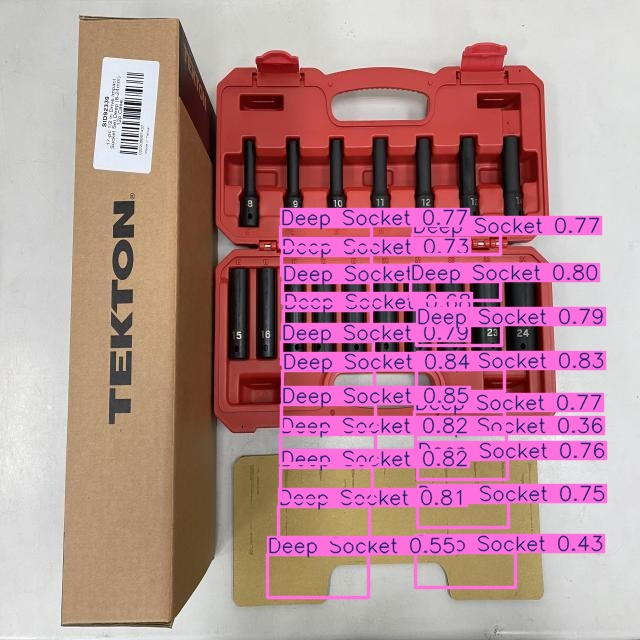

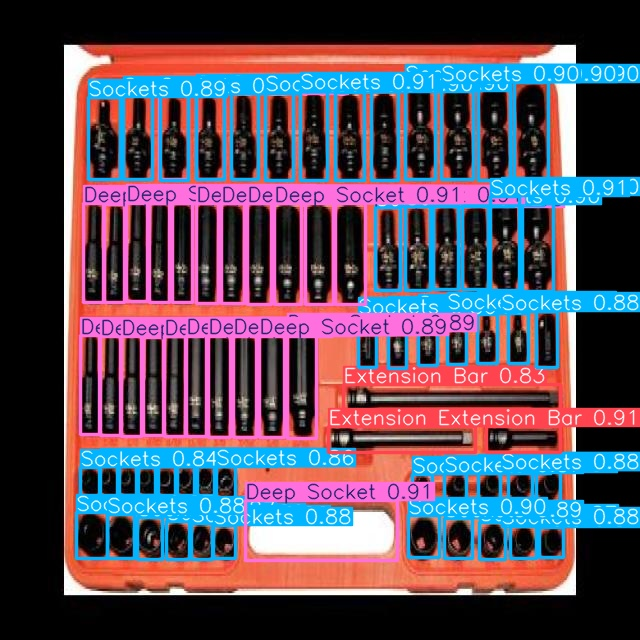

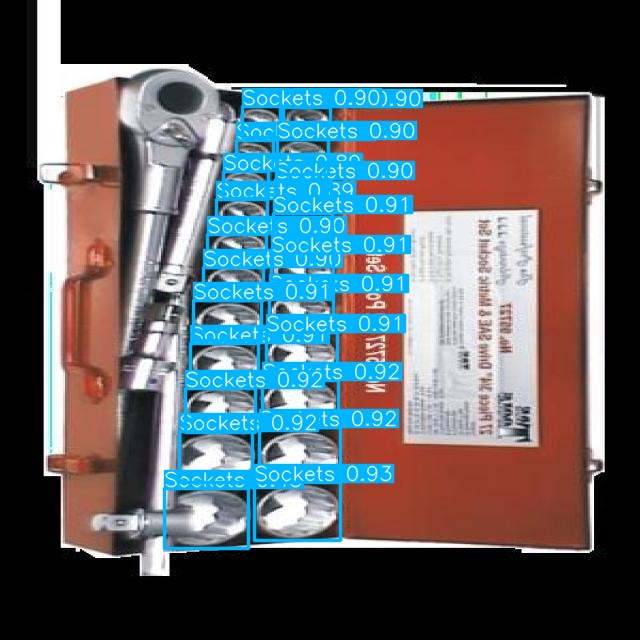

In [13]:
import glob
from IPython.display import Image, display

# Define the base path where the folders are located
base_path = '/content/runs/detect/'

# List all directories that start with 'predict' in the base path
subfolders = [os.path.join(base_path, d) for d in os.listdir(base_path)
              if os.path.isdir(os.path.join(base_path, d)) and d.startswith('predict')]

# Find the latest folder by modification time
latest_folder = max(subfolders, key=os.path.getmtime)

image_paths = glob.glob(f'{latest_folder}/*.jpg')[:3]

# Display each image
for image_path in image_paths:
    display(Image(filename=image_path, width=600))
    print("\n")

In [17]:
from ultralytics import YOLO

# Load the trained YOLOv8 model
model = YOLO('/content/runs/detect/train/weights/best.pt')  # replace with your model path

metrics = model.val()

# Print all available results
print(metrics.results_dict)

print("Precision:", metrics.results_dict['metrics/precision(B)'])
print("Recall:", metrics.results_dict['metrics/recall(B)'])
print("mAP@0.5:", metrics.results_dict['metrics/mAP50(B)'])
print("mAP@0.5:0.95:", metrics.results_dict['metrics/mAP50-95(B)'])



Ultralytics YOLOv8.2.103 🚀 Python-3.10.12 torch-2.5.1+cu121 CUDA:0 (NVIDIA A100-SXM4-40GB, 40442MiB)
Model summary (fused): 168 layers, 11,131,002 parameters, 0 gradients, 28.5 GFLOPs


val: Scanning /content/YOLV5-Detection-2/valid/labels.cache... 284 images, 0 backgrounds, 0 corrupt: 100%|██████████| 284/284 [00:00<?, ?it/s]

WARNING ⚠️ Box and segment counts should be equal, but got len(segments) = 497, len(boxes) = 8369. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.



                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 18/18 [00:08<00:00,  2.15it/s]


                   all        284       8369      0.913      0.896      0.926      0.731
               Adaptor         34         48      0.927      0.791      0.853      0.707
             Allen Key          6          6       0.83          1      0.995      0.873
            Bit Holder          7          8      0.896       0.75      0.758      0.609
           Bit Sockets         37        601      0.994      0.952      0.986      0.792
                  Bits         31        534        0.9      0.824       0.91      0.524
           Deep Socket        144       1981      0.916      0.791       0.86      0.698
         Extension Bar        178        500      0.951      0.914      0.955      0.735
           Flex Handle         13         13      0.805      0.846      0.844       0.66
        Rachet-Handels        162        200      0.943      0.908      0.945      0.764
              S Handle          4          4      0.771          1      0.995      0.835
               Socket

In [18]:
metrics = model.val()

precision = metrics.results_dict['metrics/precision(B)']
recall = metrics.results_dict['metrics/recall(B)']

# Calculate F1 score: 2 * (precision * recall) / (precision + recall)
f1_score = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0

print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1_score:.4f}")


Ultralytics YOLOv8.2.103 🚀 Python-3.10.12 torch-2.5.1+cu121 CUDA:0 (NVIDIA A100-SXM4-40GB, 40442MiB)


val: Scanning /content/YOLV5-Detection-2/valid/labels.cache... 284 images, 0 backgrounds, 0 corrupt: 100%|██████████| 284/284 [00:00<?, ?it/s]

WARNING ⚠️ Box and segment counts should be equal, but got len(segments) = 497, len(boxes) = 8369. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.



                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 18/18 [00:08<00:00,  2.14it/s]


                   all        284       8369      0.913      0.896      0.926      0.731
               Adaptor         34         48      0.927      0.791      0.853      0.707
             Allen Key          6          6       0.83          1      0.995      0.873
            Bit Holder          7          8      0.896       0.75      0.758      0.609
           Bit Sockets         37        601      0.994      0.952      0.986      0.792
                  Bits         31        534        0.9      0.824       0.91      0.524
           Deep Socket        144       1981      0.916      0.791       0.86      0.698
         Extension Bar        178        500      0.951      0.914      0.955      0.735
           Flex Handle         13         13      0.805      0.846      0.844       0.66
        Rachet-Handels        162        200      0.943      0.908      0.945      0.764
              S Handle          4          4      0.771          1      0.995      0.835
               Socket

In [22]:
metrics = model.val()

print(f"Average mAP@0.5: {metrics.results_dict['metrics/mAP50(B)']:.4f}")
print(f"Average mAP@0.5:0.95: {metrics.results_dict['metrics/mAP50-95(B)']:.4f}")


Ultralytics YOLOv8.2.103 🚀 Python-3.10.12 torch-2.5.1+cu121 CUDA:0 (NVIDIA A100-SXM4-40GB, 40442MiB)


val: Scanning /content/YOLV5-Detection-2/valid/labels.cache... 284 images, 0 backgrounds, 0 corrupt: 100%|██████████| 284/284 [00:00<?, ?it/s]

WARNING ⚠️ Box and segment counts should be equal, but got len(segments) = 497, len(boxes) = 8369. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.



                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 18/18 [00:08<00:00,  2.12it/s]


                   all        284       8369      0.913      0.896      0.926      0.731
               Adaptor         34         48      0.927      0.791      0.853      0.707
             Allen Key          6          6       0.83          1      0.995      0.873
            Bit Holder          7          8      0.896       0.75      0.758      0.609
           Bit Sockets         37        601      0.994      0.952      0.986      0.792
                  Bits         31        534        0.9      0.824       0.91      0.524
           Deep Socket        144       1981      0.916      0.791       0.86      0.698
         Extension Bar        178        500      0.951      0.914      0.955      0.735
           Flex Handle         13         13      0.805      0.846      0.844       0.66
        Rachet-Handels        162        200      0.943      0.908      0.945      0.764
              S Handle          4          4      0.771          1      0.995      0.835
               Socket